## 1. Data Ingestion and Preprocessing

In this section, we import the raw historical data from **Station 1413** and format it for subsequent time-series analysis. 

### Key Actions Performed:
* **File Ingestion:** Loaded the Excel spreadsheet while skipping the first row (`skiprows=1`) to filter out the file's main title and isolate the data table header.
* **Column Renaming:** Standardized headers to clean, concise English names (`datetime` and `q_m3s` for flow rate in cubic meters per second) to streamline data manipulation.
* **Datetime Normalization:** Converted the string timestamps into actual datetime objects using the specific format `%d/%m/%Y %H:%M`. We then applied `.dt.normalize()` to strip away the hourly timestamps (e.g., setting hours to `00:00`), keeping only the calendar date.
* **Data Verification:** Printed basic dataset structures, dimensions, and date ranges to ensure accuracy. 

> **Note on Data Completeness:** The total row count represents the length of the dataset matrix. It confirms the structure is loaded, but does not guarantee every calendar day within the period contains valid, non-null measurements.


In [1]:
import pandas as pd 

# Load raw dataset and fix headers
raw = pd.read_excel("../data/raw/Historicos-Estacion 1413.xlsx", skiprows=1)
raw.columns = ["datetime", "q_m3s"]

# Parse and normalize timestamps to daily dates
raw["date"] = pd.to_datetime(raw["datetime"], format="%d/%m/%Y %H:%M").dt.normalize() 

# Metadata and formatting check
raw.info() 
display(raw.head())   

# Temporal range and structural properties
print('First recorded date: ', raw["date"].min())
print('Last recorded date: ', raw["date"].max())
print("Rows:", len(raw))

<class 'pandas.DataFrame'>
RangeIndex: 25464 entries, 0 to 25463
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   datetime  25464 non-null  str           
 1   q_m3s     25464 non-null  float64       
 2   date      25464 non-null  datetime64[us]
dtypes: datetime64[us](1), float64(1), str(1)
memory usage: 596.9 KB


,datetime,q_m3s,date
0,01/07/1956 09:00,17.0,1956-07-01
1,02/07/1956 09:00,17.0,1956-07-02
2,03/07/1956 09:00,17.0,1956-07-03
3,04/07/1956 09:00,18.0,1956-07-04
4,05/07/1956 09:00,19.0,1956-07-05


First recorded date:  1956-07-01 00:00:00
Last recorded date:  2026-06-30 00:00:00
Rows: 25464


## 1.1 Time-series continuity and quality control

To assess the integrity of our historical records, we evaluate the dataset's continuity. We calculate the expected number of calendar days between the first and last recorded dates and cross-reference this against our row count to detect missing time-steps. Additionally, we need to check two things:
 1) We look for zero or negative values in column 'q_m3s': An error in the flow sensor could trigger a negative value, which is impossible.
 2) We look for repeated dates in column 'date': If there are repeated dates in said column, this would underestimate the actual number of missing days.

### Key Actions Performed:
* **Expected days:** Total number of calendar days spanned in the dataset.
* **Missing days:** The difference between the expected calendar days and the actual number of rows.
* **Repeated dates:** A repeated date could occupy the place of a missing date, underestimating the actual number of missing days. 
* **Percentage of missing days:** It is interesting to check this value, in order to determine if the raw dataset has a high number of missing days. 



In [2]:
# Determine the expected calendar days spanned
expected_days = (raw["date"].max() - raw["date"].min()).days + 1
print("Expected days:", expected_days)

# Determine the number of missing days
missing_days = expected_days - len(raw)
print("Missing days:", missing_days)

# Check if there are zero or negative values in column 'q_m3s'.
print("Zero or negative values:", (raw["q_m3s"] <= 0).sum())

# Check if there are duplicated dates in column 'date'
print("Duplicated dates:", raw["date"].duplicated().sum())

# Calculate the final percetange of missing days
print("Percentage of missing days:", round(missing_days/expected_days * 100,3), '%')


Expected days: 25567
Missing days: 103
Zero or negative values: 0
Duplicated dates: 0
Percentage of missing days: 0.403 %


## 1.2 Locating and sorting missing days 

After calculating the number of expected, missing, zero or negative and duplicated days, now it is necessary to determine where those missing days are located. In order to achieve this, we will create a range named 'full_calendar' which goes from the 1st to the last date recorded, with a frequency of 1 day. Then, we will determine the number of missing dates (stored in 'missing_dates'). After this, we check if the previous value stored in 'missing_days' (calculated doing: expected_days - len(raw)) equals missing_dates (obtained with the "range method").
Finally, we count and organize the missing dates, sorting them by year. 

### Key Actions Performed:
* **Range:** We create a range stored in 'full_calendar', that goes from the 1st to the last date, and with a daily frequency.
* **Quantity of missing dates:** Even though we already calculated the number of missing dates doing (expected_days - len(raw)), we need to check if the quantity of missing dates coming from both methods ("difference and range" methods) are the same.
* **Number of missing dates per year:** From all the missing dates obtained previously, we classify them by the year those "missing spaces" are located. 



In [3]:
# Create a range with start and end point, and frequency
full_calendar = pd.date_range(start= raw["date"].min() , end= raw["date"].max() ,freq= '1D')

# Identify the missing dates and obtain the quantity
missing_dates=full_calendar[~full_calendar.isin(raw['date'])]
print(missing_dates)
print('Quantity of missing dates: ',len(missing_dates))

# Check is missing_dates == missing_days
if len(missing_dates) == missing_days:
    print('Both values are equal')
else:
    print('Values are not equal ')

# Sort the missing dates by year
missing_dates.year.value_counts().sort_index()

DatetimeIndex(['1962-09-01', '1962-09-02', '1962-09-03', '1962-09-04',
               '1962-09-05', '1962-09-06', '1962-09-07', '1962-09-08',
               '1962-09-09', '1962-09-10',
               ...
               '1985-06-22', '1985-06-23', '1985-06-24', '1985-06-25',
               '1985-06-26', '1985-06-27', '1985-06-28', '1985-06-29',
               '1985-06-30', '2023-06-18'],
              dtype='datetime64[us]', length=103, freq=None)
Quantity of missing dates:  103
Both values are equal


1962    30
1970     2
1976    40
1985    30
2023     1
Name: count, dtype: int64

## 1.3 Interpolating missing days 

After locating and sorting the missing days, we need to use a linear interpolation model to fill the flow values of the missing dates (in other words, filling the "q_m3s values" of the missing dates). To achieve this, we follow the sequence:
 1) We define series "q" which makes the column 'date' the index of the table. 
 2) After, we force the table to have exactly the rows of a given index (using 'reindex'), which makes the missing dates to appear as 'NaN'. 
 3) The fact that the missing dates appear as 'NaN' is useful to create a flag called 'filled' which has 2 possible values: True / False. Incorporating a flag is necessary to differentiate the 'filled' values from the 'measured data'.
 4) Finally, we check the following:  A) There is 0 NaN after interpolating ; B) There are 103 filled dates ; C) Visual inspection of the filled gap [in this particular case: 1976-06-18:1976-08-02]

### Key Actions Performed:
* **Set index:** We define a series 'q' that correlates the values in column 'q_m3s' with the new index: 'date'.
* **Reindex:** By forcing the table to have exactly the rows of a given index, the rows related with the missing dates are created, and 'NaN' appears in them.
* **Interpolate:** Allows us to use a linear interpolation model to fill the flow values of the missing dates. We use the 'time' method, which interpolates based on the distance between the dates.



In [4]:
# Define series 'q' , which correlates the values in column 'q_m3s' with the new index: 'dates'
q = raw.set_index("date")["q_m3s"]

# Use reindex to generate the rows related with the missing dates
q = q.reindex(full_calendar)

# Create the flag 'filled' to recognize if the value is measured or interpolated
filled = q.isna()

# Use 'time' method for linear interpolation
q=q.interpolate(method="time")
print(q)    

# Verifications: 
print("NaN after interpolation:", q.isna().sum())   # must be 0 [means all NaN have been filled]
print("Filled days:", filled.sum())                  # must be 103 [missing dates]
display(q["1976-06-18":"1976-08-02"])                # look inside the longest gap to check if the interpolation was executed

1956-07-01    17.00
1956-07-02    17.00
1956-07-03    17.00
1956-07-04    18.00
1956-07-05    19.00
              ...  
2026-06-26    22.17
2026-06-27    22.14
2026-06-28    21.37
2026-06-29    21.72
2026-06-30    21.66
Freq: D, Name: q_m3s, Length: 25567, dtype: float64
NaN after interpolation: 0
Filled days: 103


1976-06-18    16.800000
1976-06-19    17.000000
1976-06-20    17.200000
1976-06-21    17.200000
1976-06-22    17.187805
1976-06-23    17.175610
1976-06-24    17.163415
1976-06-25    17.151220
1976-06-26    17.139024
1976-06-27    17.126829
1976-06-28    17.114634
1976-06-29    17.102439
1976-06-30    17.090244
1976-07-01    17.078049
1976-07-02    17.065854
1976-07-03    17.053659
1976-07-04    17.041463
1976-07-05    17.029268
1976-07-06    17.017073
1976-07-07    17.004878
1976-07-08    16.992683
1976-07-09    16.980488
1976-07-10    16.968293
1976-07-11    16.956098
1976-07-12    16.943902
1976-07-13    16.931707
1976-07-14    16.919512
1976-07-15    16.907317
1976-07-16    16.895122
1976-07-17    16.882927
1976-07-18    16.870732
1976-07-19    16.858537
1976-07-20    16.846341
1976-07-21    16.834146
1976-07-22    16.821951
1976-07-23    16.809756
1976-07-24    16.797561
1976-07-25    16.785366
1976-07-26    16.773171
1976-07-27    16.760976
1976-07-28    16.748780
1976-07-29    16

## 1.4 Plotting historical data

In this section, we import the matplotlib library and plot the date vs daily mean flow (m3/s) to visualize the historical data.

### Key Actions Performed:
* **Import Matplotlib:** Matplotlib is an open-source library for creating interactive data visualization resources. 
* **Fig parameters:** 14x4 fig size: wide format for a long series.
* **Data parameters:** There are 2 kind of points: A) Measured points (in blue, united by a line). B) Interpolated points (in red, shown as single points).
* **Axes:** 2 axes: 'Date' as the horizontal axis, and 'Daily mean flow (m³/s)' as the vertical axis
* **Rest of parameters:** Such as the plot title and legends.

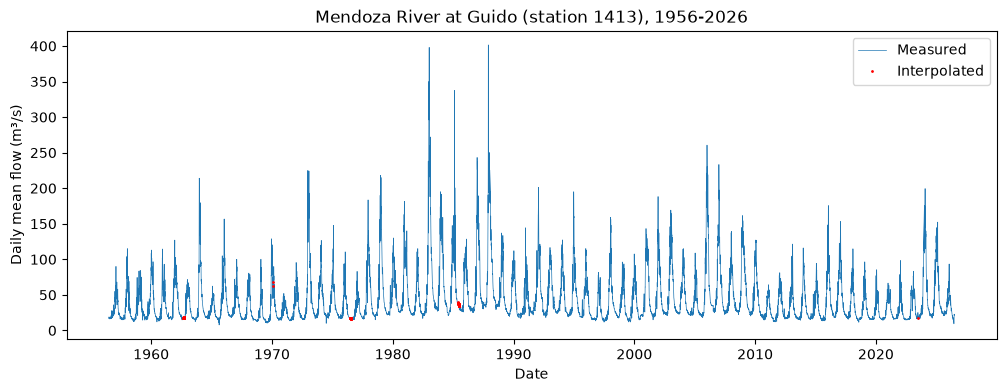

In [ ]:
# Import matplotlib
import matplotlib.pyplot as plt

# Creating the graph
fig, ax = plt.subplots(figsize=(14,4))

# Define both kind of values, measured and interpolated
ax.plot(q.index, q, linewidth=0.5, label="Measured")
ax.plot(q[filled].index, q[filled], ".", color="red", markersize=2, label="Interpolated")

# Name both axes
ax.set_xlabel("Date")
ax.set_ylabel("Daily mean flow (m³/s)")

# Define set title and legend
ax.set_title("Mendoza River at Guido (station 1413), 1956-2026")
ax.legend()

# Show graph
plt.show()

## 1.5 Determining wet and dry years

In this section, we determine various and useful parameters such as the means and medians of the different individual years and decades.
First, we obtain the annual average flow rate (mean), strictly from the complete calendar years (the first and last year,which are incomplete, will not be taken in account). Then, we sort those average flow rates and select the 5 wettest years.

After this, we can also calculate the mean of each decade and also sort these values. This will also give us useful information regarding the dry and wet decades. Added to this, the median of the average flow rates will be used as a threshold to determine if a particular year is considered as dry or wet. This means that we are going to be using our own criteria: If the average flow rate is less than the previously obtained median (lower half of the 69 average flows), the year will be considered as dry. Otherwise, it will be considered as wet. 

### Key Actions Performed:
* **Annual average flow rate, based on complete years:** For each complete year, the average flow rate is calculated. For the years at the ends of the series, it does not make sense to calculate the average flow rate.
* **Average flow rate per decade:** In the same way that the average flow rate was calculated for each full year, the same process is applied to the decades. This allows us to determine which decades are dry and which are wet.
* **median as a threshold and for dry/wet classification:** As previously explained, the median of the annual average flow rates is used as a threshold to determine whether a given year is dry or wet. If a year falls below this median, it is considered to be in the "first half" of the data and is therefore classified as a dry year. Otherwise, it is considered a wet year.




In [63]:
# Determining and interpreting the wet and dry years

    # Determining the mean of the individual years and decades
annual_mean = q.groupby(q.index.year).mean() # mean flow of each calendar year
annual_mean = annual_mean.loc[1957:2025]   # keep complete calendar years only -> does not consider incomplete years
display('5 WETTEST YEARS:',annual_mean.sort_values(ascending=False).head(5)) # 5 wettest years
display('5 DRIEST YEARS:',annual_mean.sort_values(ascending=True).head(5)) # 5 driest years

decade_mean = annual_mean.groupby((annual_mean.index // 10)*10).mean()  # Determine the mean flow for each decade
display('MEAN FLOW BY DECADE:',decade_mean.sort_values(ascending=False).round(1))  # mean flow by decade

    # Determining the median of the annual averages.
median_flow = annual_mean.median() # median calculated from the 69 annual means. "central" mean
print("Median annual flow, threshold:", round(median_flow, 1))

dry_years = annual_mean[annual_mean < median_flow]   # Create a list and keep only the years below the median
print("Dry years:", dry_years.index.tolist())  # Print only the dry years, to count them

'5 WETTEST YEARS:'

1983    90.839726
1987    87.958329
2006    73.122712
1988    72.665738
1984    64.765191
Name: q_m3s, dtype: float64

'5 DRIEST YEARS:'

1971    25.873699
1968    26.699180
2022    27.351973
2021    27.967726
2011    28.431616
Name: q_m3s, dtype: float64

'MEAN FLOW BY DECADE:'

1980    64.4
2000    53.3
1990    42.4
1970    40.6
2020    37.9
2010    35.3
1960    35.0
1950    33.6
Name: q_m3s, dtype: float64

Median annual flow, threshold: 40.6
Dry years: [1957, 1958, 1959, 1960, 1961, 1962, 1963, 1964, 1965, 1967, 1968, 1969, 1970, 1971, 1972, 1975, 1976, 1990, 1996, 1997, 1999, 2004, 2010, 2011, 2012, 2013, 2014, 2015, 2018, 2019, 2020, 2021, 2022, 2023]


### Interpretation
1)  Peaks clearly occur in warmer seasons: the line starts rising in spring (September to December) and presents its highest peaks in summer (January to March). This corresponds completely with the fact that river discharge depends primarily on seasonal snowmelt, while the remainder comes from glacial melt and rainfall, as stated by Pensado (2016) and Salomón et al. (2005), and cited in "Análisis de Factibilidad de Fondo de Agua en la Cuenca del Río Mendoza", p. 13. 

2) The 5 wettest years are: 1983 (with an average flow rate of 90.8 m3/s) ; 1987 (with an average flow rate of 88.0 m3/s) ; 2006 (with an average flow rate of 73.1 m3/s) ; 1988 (with an average flow rate of 72.7 m3/s) ; 1984 (with an average flow rate of 64.8 m3/s). We can also analyze the driest year which is 1971 (with an average flow rate of 25.9 m3/s)

3) When comparing the period from 2010 to 2020 with other decades, the average for the 2010s (35.3) is almost the same as that of the 1960s (35.0). The 2010s were dry, but comparable to the 1960s. 
Using our own criteria, we can see that there is a streak of 6 dry years between 2010 and 2015, and there is another streak of 6 consecutive dry years between 2018 and 2023. 
It is worth noting that a stretch of dry years is not a unique feature of the 2010–2020 decade. Other decades exhibit this same pattern: 
    A) 1957–1972 contains 15 dry years out of 16; only 1966 is above the median. 
    B) The 1957 streak starts at the beginning of the record, so its true length may be longer.
    C) From 1967 to 1972, there is another such sequence, lasting 6 years.

4) Regarding interpolation:  interpolated points (in red) show logical values, with no outliers. 